In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [12]:
#exercise 1.1
cdns = pd.read_csv('/Users/murad/Desktop/Karlov/Semester I/Python/my_stuff_env/data_ws2026/CDNS.csv')
crm = pd.read_csv('/Users/murad/Desktop/Karlov/Semester I/Python/my_stuff_env/data_ws2026/CRM.csv')
fis = pd.read_csv('/Users/murad/Desktop/Karlov/Semester I/Python/my_stuff_env/data_ws2026/FIS.csv')
hig = pd.read_csv('/Users/murad/Desktop/Karlov/Semester I/Python/my_stuff_env/data_ws2026/HIG.csv')
df = pd.concat([cdns,crm, fis , hig])
cdns["Ticker"] = "CDNS"
crm["Ticker"] = "CRM"
fis["Ticker"] = "FIS"
hig["Ticker"] = "HIG"
df = pd.concat([cdns, crm, fis, hig])

# Is there a company that has no difference between the High and Low columns forr andy trading day? What does it mean for the stock’s trading behavior on such?
print(df.loc[df["High"] == df["Low"]])
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date")

            Date     Open     High      Low    Close   Volume  Dividends  \
0     2022-01-03  185.680  188.570  181.880  183.160  1104200        0.0   
1     2022-01-04  182.190  183.680  174.330  178.300  1690800        0.0   
2     2022-01-05  176.570  178.710  172.060  172.620  1733300        0.0   
3     2022-01-06  171.750  175.220  170.530  173.120  1443000        0.0   
4     2022-01-07  171.550  172.640  165.930  166.020  1590200        0.0   
...          ...      ...      ...      ...      ...      ...        ...   
997   2025-12-23  138.031  138.633  136.650  137.232  1123600        0.0   
998   2025-12-24  137.094  138.564  136.472  137.863   674900        0.0   
999   2025-12-26  137.646  138.150  136.679  136.827   511000        0.0   
1000  2025-12-29  137.104  137.340  136.433  136.965   877100        0.0   
1001  2025-12-30  136.975  137.271  136.551  136.995   484800        0.0   

      Stock Splits Ticker  
0              0.0   CDNS  
1              0.0   CDNS  
2  

In [13]:
print(df)

               Open     High      Low    Close   Volume  Dividends  \
Date                                                                 
2022-01-03  185.680  188.570  181.880  183.160  1104200        0.0   
2022-01-04  182.190  183.680  174.330  178.300  1690800        0.0   
2022-01-05  176.570  178.710  172.060  172.620  1733300        0.0   
2022-01-06  171.750  175.220  170.530  173.120  1443000        0.0   
2022-01-07  171.550  172.640  165.930  166.020  1590200        0.0   
...             ...      ...      ...      ...      ...        ...   
2025-12-23  138.031  138.633  136.650  137.232  1123600        0.0   
2025-12-24  137.094  138.564  136.472  137.863   674900        0.0   
2025-12-26  137.646  138.150  136.679  136.827   511000        0.0   
2025-12-29  137.104  137.340  136.433  136.965   877100        0.0   
2025-12-30  136.975  137.271  136.551  136.995   484800        0.0   

            Stock Splits Ticker  
Date                             
2022-01-03           

In [9]:
#What is the highest and lowest price price each company recorded? Hint:Select the column(s) that can contain the maximum and minimum price wisely.
highest = df.groupby("Ticker")["High"].max()
lowest = df.groupby("Ticker")["High"].min()
print(highest)
print(lowest)

Ticker
CDNS    376.450
CRM     363.695
FIS     107.150
HIG     138.633
Name: High, dtype: float64
Ticker
CDNS    136.940
CRM     127.113
FIS      44.461
HIG      57.457
Name: High, dtype: float64


In [46]:
# Calculate logarithmic returns from Close. For each company, report min mean, standard deviation, andd skewness of returns.,
max
df["rets"] = np.log(df["Close"] / df.groupby("Ticker")["Close"].shift(1))
df["rets"].agg(["min", "max", "mean", "std", "skew"])


min    -0.329168
max     0.133224
mean    0.000235
std     0.020817
skew   -1.366979
Name: rets, dtype: float64

In [ ]:
#Which company recorded the lowest total logarithmic return over the whole period?

In [27]:
#(2 pt) What is the median calendar weekly volume (i.e. sum of volume for a particular week) for each company? Hint: check resample.
weeklyvols = df.groupby("Ticker")["Volume"].resample("W").sum()
print(weeklyvols)
print(np.median(weeklyvols))
print(weeklyvols.median())

Ticker  Date      
CDNS    2022-01-09     7561500
        2022-01-16     7351800
        2022-01-23     7765400
        2022-01-30    10378000
        2022-02-06     7806100
                        ...   
HIG     2025-12-07     9014100
        2025-12-14     8209600
        2025-12-21    11675300
        2025-12-28     3290600
        2026-01-04     1361900
Name: Volume, Length: 836, dtype: int64
12496550.0
12496550.0


In [29]:
#7. (2 pt) Create a new column volume_class with categories (e.g., “Low”, “Medium”,“High”) based on volume tertiles within the given company.
df["volume_class"] = pd.qcut(df["Volume"], q=3, labels=["Low", "Medium", "High"])
print(df)


               Open     High      Low    Close   Volume  Dividends  \
Date                                                                 
2022-01-03  185.680  188.570  181.880  183.160  1104200        0.0   
2022-01-04  182.190  183.680  174.330  178.300  1690800        0.0   
2022-01-05  176.570  178.710  172.060  172.620  1733300        0.0   
2022-01-06  171.750  175.220  170.530  173.120  1443000        0.0   
2022-01-07  171.550  172.640  165.930  166.020  1590200        0.0   
...             ...      ...      ...      ...      ...        ...   
2025-12-23  138.031  138.633  136.650  137.232  1123600        0.0   
2025-12-24  137.094  138.564  136.472  137.863   674900        0.0   
2025-12-26  137.646  138.150  136.679  136.827   511000        0.0   
2025-12-29  137.104  137.340  136.433  136.965   877100        0.0   
2025-12-30  136.975  137.271  136.551  136.995   484800        0.0   

            Stock Splits Ticker volume_class  
Date                                      

In [32]:
#proboem 2
dfcomp = pd.read_csv('/Users/murad/Desktop/Karlov/Semester I/Python/my_stuff_env/companies_no_subindustry.csv')
print(dfcomp)
#(1 pt) How many companies have missing inclusion dates (included column)?
dfcomp.isna().sum()

    Symbol              Security             GICS_Sector  \
0      MMM                    3M             Industrials   
1      AOS           A. O. Smith             Industrials   
2      ABT                Abbott             Health Care   
3     ABBV                AbbVie             Health Care   
4     ABMD               Abiomed             Health Care   
..     ...                   ...                     ...   
498    YUM           Yum! Brands  Consumer Discretionary   
499   ZBRA    Zebra Technologies  Information Technology   
500    ZBH         Zimmer Biomet             Health Care   
501   ZION  Zions Bancorporation              Financials   
502    ZTS                Zoetis             Health Care   

                          hq    included      Founded  
0      Saint Paul, Minnesota  09.08.1976         1902  
1       Milwaukee, Wisconsin  26.07.2017         1916  
2    North Chicago, Illinois  31.03.1964         1888  
3    North Chicago, Illinois  31.12.2012  2013 (1888)  

Symbol          0
Security        0
GICS_Sector     0
hq              0
included       45
Founded         0
dtype: int64

In [40]:
dfcomp = dfcomp.dropna()
dfcomp["included"] = pd.to_datetime(dfcomp["included"], format='mixed', errors="coerce")
dfcomp["age"] =dfcomp["included"] - pd.to_datetime(dfcomp["Founded"], format='mixed', errors="coerce" )
print(dfcomp["age"])

0     27279 days
1     37097 days
2     27848 days
4     13664 days
5      8192 days
         ...    
498     160 days
499   18618 days
500   27217 days
501   46923 days
502   22452 days
Name: age, Length: 421, dtype: timedelta64[us]


In [56]:
dfcomp = dfcomp.set_index("Symbol")
print("youngest:", dfcomp["age"].idxmin())
print("Oldest:", dfcomp["age"].idxmax())
print(dfcomp["age"].median() / 365)

youngest: HWM
Oldest: BK
38 days 08:44:42.739726


In [57]:
dfcomp.groupby("GICS_Sector").value_counts()


GICS_Sector             Security                 hq                         included    Founded  age       
Communication Services  Alphabet Inc. (Class C)  Mountain View, California  2006-03-04  1998     2984 days     1
                        Match Group              Dallas, Texas              2021-09-20  1986     13046 days    1
                        Alphabet Inc. (Class A)  Mountain View, California  2014-03-04  1998     5906 days     1
                        Meta Platforms           Menlo Park, California     2013-12-23  2004     3644 days     1
                        Take-Two Interactive     New York City, New York    2018-03-19  1993     9208 days     1
                                                                                                              ..
Utilities               Ameren                   St. Louis, Missouri        1991-09-19  1902     32768 days    1
                        Atmos Energy             Dallas, Texas              2019-02-15  1906     4131

/var/folders/mb/_1f2msgn2dn0p1jp4lld0p7c0000gn/T/ipykernel_75881/3179028491.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


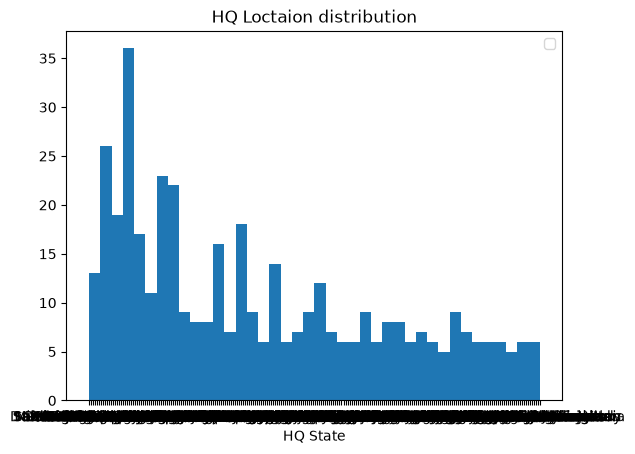

In [61]:
#(2 pt) Parse the hq column to extract the state and describe its distribution (e.g.,bar plot).
fig, ax = plt.subplots()
ax.hist(dfcomp["hq"], bins=40)
ax.set_xlabel("HQ State")
ax.legend()
ax.set_title("HQ Loctaion distribution")
plt.show()

In [63]:
dfcomp1 = pd.read_csv("/Users/murad/Downloads/companies_subindustry.csv")
dfcomp2 = pd.concat([dfcomp, dfcomp1])
print(dfcomp2)

         Security             GICS_Sector                       hq   included  \
MMM            3M             Industrials    Saint Paul, Minnesota 1976-09-08   
AOS   A. O. Smith             Industrials     Milwaukee, Wisconsin 2017-07-26   
ABT        Abbott             Health Care  North Chicago, Illinois 1964-03-31   
ABMD      Abiomed             Health Care   Danvers, Massachusetts 2018-05-31   
ACN     Accenture  Information Technology          Dublin, Ireland 2011-06-07   
...           ...                     ...                      ...        ...   
498           NaN                     NaN                      NaN        NaT   
499           NaN                     NaN                      NaN        NaT   
500           NaN                     NaN                      NaN        NaT   
501           NaN                     NaN                      NaN        NaT   
502           NaN                     NaN                      NaN        NaT   

     Founded        age Sym

In [ ]:
#problem3
Generate four random variables from four different distributions (e.g., Normal,
Uniform, etc.), each with a random number of observations between 100 and 500.
x1 = 